# Régression polynomiale multivariée — Advertising

Prédire `Sales` à partir de `TV`, `Radio` et `Newspaper`.

1. Choisir le degré avec trois techniques (sklearn)
2. Modèle polynomial **from scratch** (descente de gradient)
3. Comparaison avec la régression linéaire multiple
4. Régularisation Ridge (L2) et Lasso (L1), avec λ = 1 (sklearn)

Toutes les variables sont **normalisées** (StandardScaler, ajusté sur le train uniquement).

## 0. Données

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, cross_val_score, learning_curve
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

data = pd.read_csv("data/Advertising.csv")
X = data[["TV", "Radio", "Newspaper"]].values
y = data["Sales"].values

# 80 % entraînement, 20 % test (le test n'est utilisé qu'à la fin)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
data.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


## 1. Choix du degré : trois techniques

Le pipeline `PolynomialFeatures → StandardScaler → LinearRegression` recalcule la normalisation à chaque ajustement, donc sans fuite de données.

In [2]:
degrees = range(1, 7)

def poly_model(degree, regressor=None):
    return make_pipeline(PolynomialFeatures(degree, include_bias=False),
                         StandardScaler(),
                         regressor or LinearRegression())

### Technique 1 — Ensemble de validation (hold-out)

On réserve une partie du train pour valider.

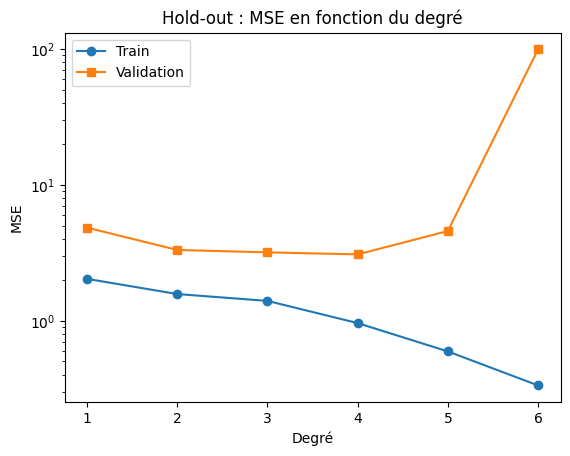

Meilleur degré (hold-out) : 4


In [3]:
X_a, X_val, y_a, y_val = train_test_split(X_train, y_train, test_size=0.25, random_state=0)

train_err, val_err = [], []
for d in degrees:
    m = poly_model(d).fit(X_a, y_a)
    train_err.append(mean_squared_error(y_a, m.predict(X_a)))
    val_err.append(mean_squared_error(y_val, m.predict(X_val)))

plt.plot(degrees, train_err, "o-", label="Train")
plt.plot(degrees, val_err, "s-", label="Validation")
plt.yscale("log"); plt.xlabel("Degré"); plt.ylabel("MSE"); plt.legend()
plt.title("Hold-out : MSE en fonction du degré"); plt.show()
print("Meilleur degré (hold-out) :", list(degrees)[int(np.argmin(val_err))])

### Technique 2 — Validation croisée K-Fold (K = 5)

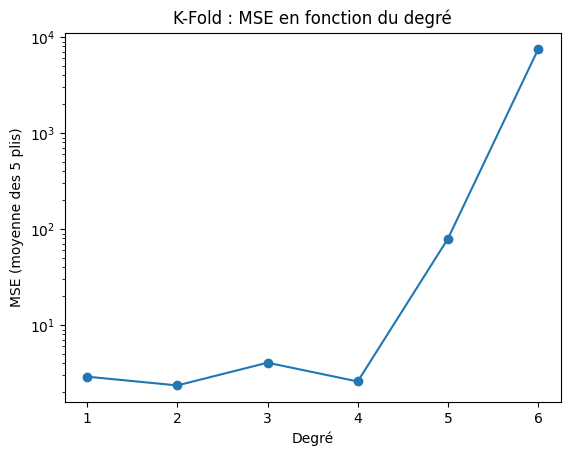

Meilleur degré (K-Fold) : 2


In [4]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_err = [-cross_val_score(poly_model(d), X_train, y_train, cv=kf,
                           scoring="neg_mean_squared_error").mean() for d in degrees]

plt.plot(degrees, cv_err, "o-")
plt.yscale("log"); plt.xlabel("Degré"); plt.ylabel("MSE (moyenne des 5 plis)")
plt.title("K-Fold : MSE en fonction du degré"); plt.show()
print("Meilleur degré (K-Fold) :", list(degrees)[int(np.argmin(cv_err))])

### Technique 3 — Courbes d'apprentissage

Erreur train et validation en fonction de la taille de l'échantillon, pour un degré trop simple (1), le degré 2 et un degré trop complexe (5).

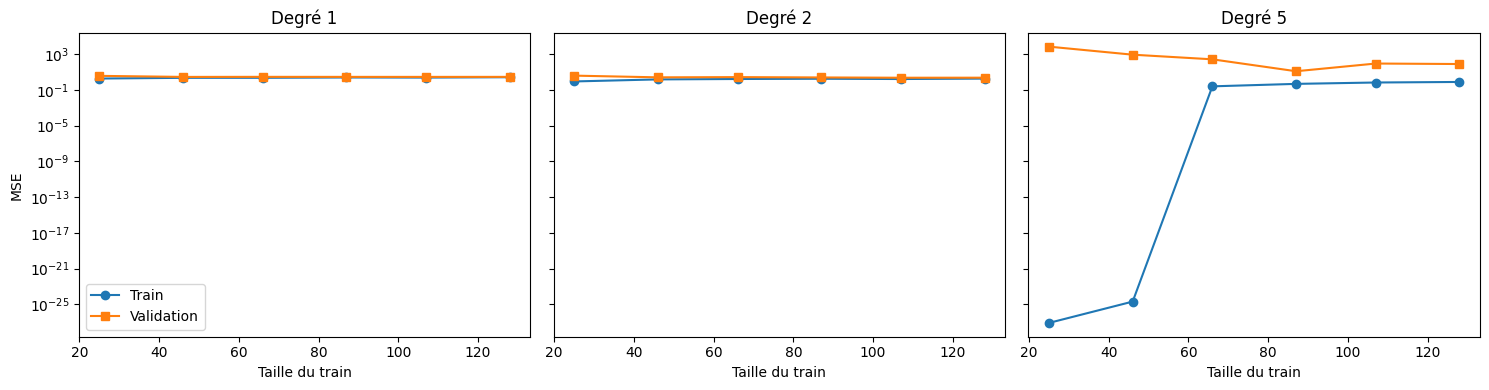

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, d in zip(axes, [1, 2, 5]):
    sizes, tr, va = learning_curve(poly_model(d), X_train, y_train, cv=kf,
                                   train_sizes=np.linspace(0.2, 1, 6),
                                   scoring="neg_mean_squared_error")
    ax.plot(sizes, -tr.mean(axis=1), "o-", label="Train")
    ax.plot(sizes, -va.mean(axis=1), "s-", label="Validation")
    ax.set_title(f"Degré {d}"); ax.set_xlabel("Taille du train"); ax.set_yscale("log")
axes[0].set_ylabel("MSE"); axes[0].legend()
plt.tight_layout(); plt.show()

### Décision

* **Degré 1** : sous-apprentissage (erreurs train et validation élevées).
* **Degré 2** : meilleur MSE en validation croisée, et courbes train/validation proches.
* **Degrés ≥ 5** : sur-apprentissage (l'erreur de validation explose).
* Le hold-out donne des valeurs proches pour les degrés 2 à 4 (un seul découpage, donc plus bruité) ; on retient le plus simple et le meilleur en K-Fold : **degré 2**.

In [6]:
DEGREE = 2

## 2. Régression polynomiale from scratch

Même principe que le modèle linéaire : on ajoute des colonnes (puissances et produits croisés) à $X$, puis un terme de biais, et on applique la descente de gradient.

$$J(\theta)=\frac{1}{2m}\sum (X\theta-y)^2 \qquad \nabla J=\frac{1}{m}X^T(X\theta-y) \qquad \theta \leftarrow \theta-\alpha\nabla J$$

In [7]:
from itertools import combinations_with_replacement

def poly_features(X, degree):
    # colonnes : tous les produits de 1 à `degree` variables (x1, x2, x1², x1·x2, ...)
    cols = [np.prod(X[:, c], axis=1)
            for d in range(1, degree + 1)
            for c in combinations_with_replacement(range(X.shape[1]), d)]
    return np.column_stack(cols)

def prepare(degree):
    # normalisation avec les statistiques du train, puis colonne de biais
    scaler = StandardScaler().fit(poly_features(X_train, degree))
    add_bias = lambda A: np.hstack((A, np.ones((A.shape[0], 1))))
    return (add_bias(scaler.transform(poly_features(X_train, degree))),
            add_bias(scaler.transform(poly_features(X_test, degree))))

def model(X, theta):
    return X.dot(theta)

def cost_function(X, y, theta):
    m = len(y)
    return 1/(2*m) * np.sum((model(X, theta) - y)**2)

def grad(X, y, theta):
    m = len(y)
    return 1/m * X.T.dot(model(X, theta) - y)

def gradient_descent(X, y, theta, learning_rate, n_iterations):
    cost_history = np.zeros(n_iterations)
    for i in range(n_iterations):
        theta = theta - learning_rate * grad(X, y, theta)
        cost_history[i] = cost_function(X, y, theta)
    return theta, cost_history

def coef_determination(y, pred):
    return 1 - ((y - pred)**2).sum() / ((y - y.mean())**2).sum()

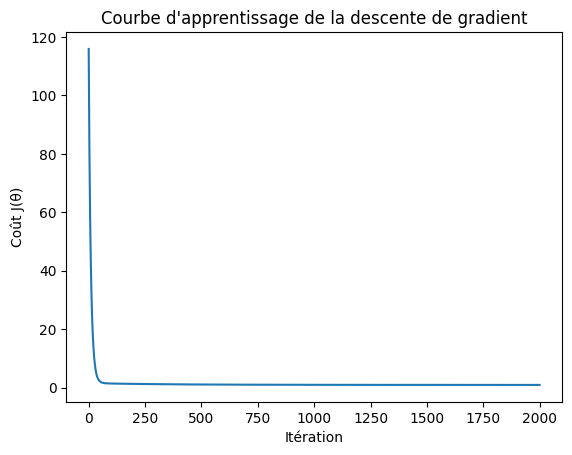

Polynomial (degré 2) : MSE test = 1.4630, R² test = 0.9527


In [8]:
y_tr, y_te = y_train.reshape(-1, 1), y_test.reshape(-1, 1)
Xp_train, Xp_test = prepare(DEGREE)

theta0 = np.zeros((Xp_train.shape[1], 1))
theta_poly, cost_history = gradient_descent(Xp_train, y_tr, theta0, learning_rate=0.05, n_iterations=2000)

plt.plot(cost_history); plt.xlabel("Itération"); plt.ylabel("Coût J(θ)")
plt.title("Courbe d'apprentissage de la descente de gradient"); plt.show()

pred_poly = model(Xp_test, theta_poly)
print(f"Polynomial (degré {DEGREE}) : MSE test = {mean_squared_error(y_te, pred_poly):.4f}, "
      f"R² test = {coef_determination(y_te, pred_poly):.4f}")

## 3. Comparaison avec la régression linéaire multiple

Même code, avec le degré 1.

In [9]:
Xl_train, Xl_test = prepare(1)
theta_lin, _ = gradient_descent(Xl_train, y_tr, np.zeros((Xl_train.shape[1], 1)), 0.05, 2000)
pred_lin = model(Xl_test, theta_lin)

results = pd.DataFrame({
    "MSE test": [mean_squared_error(y_te, pred_lin), mean_squared_error(y_te, pred_poly)],
    "R² test":  [coef_determination(y_te, pred_lin), coef_determination(y_te, pred_poly)],
}, index=["Linéaire multiple", f"Polynomial degré {DEGREE}"])
results.round(4)

,MSE test,R² test
Linéaire multiple,2.9078,0.9059
Polynomial degré 2,1.4630,0.9527


**Que choisir ?** Le modèle polynomial de degré 2 réduit l'erreur de test d'environ moitié et améliore le R² par rapport au modèle linéaire : la relation entre les budgets et les ventes n'est pas strictement linéaire (effets quadratiques et interactions, par exemple TV × Radio). Il ne coûte que 9 coefficients au lieu de 3. On choisit donc le **polynôme de degré 2**. Le modèle linéaire reste préférable seulement si l'interprétation simple prime.

## 4. Régularisation : Ridge (L2) et Lasso (L1), λ = 1

$$J_{L2}(\theta)=\text{MSE}+\lambda\sum\theta_j^2 \qquad J_{L1}(\theta)=\text{MSE}+\lambda\sum|\theta_j|$$

Modèles sklearn (paramètre `alpha` = λ = 1), toujours sur les variables polynomiales normalisées.

In [10]:
models = {
    "Polynomial (sans pénalité)": poly_model(DEGREE),
    "Ridge (L2, λ=1)": poly_model(DEGREE, Ridge(alpha=1)),
    "Lasso (L1, λ=1)": poly_model(DEGREE, Lasso(alpha=1)),
}
rows = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    pred = m.predict(X_test)
    coefs = m[-1].coef_
    rows[name] = {"MSE test": mean_squared_error(y_test, pred), "R² test": r2_score(y_test, pred),
                  "Coefficients non nuls": int(np.sum(coefs != 0)), "Somme |coef|": np.abs(coefs).sum()}
comparison = pd.DataFrame(rows).T
comparison.round(4)

,MSE test,R² test,Coefficients non nuls,Somme |coef|
Polynomial (sans pénalité),1.4425,0.9533,9.0,12.4555
"Ridge (L2, λ=1)",1.5272,0.9506,9.0,10.2539
"Lasso (L1, λ=1)",4.0031,0.8705,2.0,4.1850


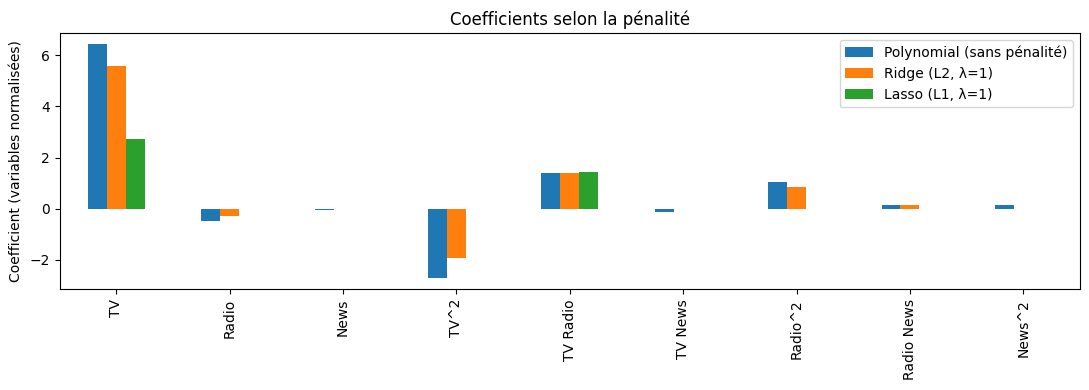

In [11]:
feature_names = PolynomialFeatures(DEGREE, include_bias=False).fit(X_train).get_feature_names_out(["TV", "Radio", "News"])
coef_table = pd.DataFrame({n: m[-1].coef_ for n, m in models.items()}, index=feature_names)
coef_table.plot.bar(figsize=(11, 4), ylabel="Coefficient (variables normalisées)", title="Coefficients selon la pénalité")
plt.tight_layout(); plt.show()

## 5. Conclusion

Résultats sur le test :

| Modèle | MSE | R² | Coefficients non nuls |
|---|---|---|---|
| Linéaire multiple | 2,91 | 0,906 | 3 |
| Polynomial degré 2 | 1,44 – 1,46 | 0,953 | 9 |
| Ridge (λ = 1) | 1,53 | 0,951 | 9 |
| Lasso (λ = 1) | 4,00 | 0,871 | 2 |

* **Degré** : K-Fold et courbes d'apprentissage retiennent le degré 2 ; le hold-out (un seul découpage) est plus bruité.
* **Polynomial vs linéaire** : le degré 2 divise l'erreur de test par 2 ; on le préfère au modèle linéaire.
* **Ridge (L2)** : réduit l'amplitude des coefficients (somme des |coef| : 12,5 → 10,3) sans en annuler aucun, pour une précision quasi identique. Il n'apporte pas de gain ici car le modèle ne sur-apprend pas au degré 2.
* **Lasso (L1)** : avec λ = 1 la pénalité est trop forte ; 7 coefficients sur 9 sont annulés et les performances chutent (R² 0,871). Il fait de la sélection de variables, mais un λ plus petit serait nécessaire pour conserver la précision.
* **Choix final** : polynôme de degré 2, avec Ridge (λ = 1) si l'on souhaite des coefficients plus stables.